In [1]:
import pandas as pd
df = pd.read_csv("ab_data.csv")
print(df.shape)
df.head()

(294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [2]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64


In [4]:
mismatch = df[
    ((df["group"] == "control") & (df["landing_page"] == "new_page"))|
    ((df["group"] == "treatment") & (df["landing_page"] == "old_page"))
]
print("mismatched rows:",len(mismatch))

mismatched rows: 3893


In [5]:
df2 = df.drop(mismatch.index)
print(df2.shape)

(290585, 5)


In [6]:
print("duplicate user_ids:",df2["user_id"].duplicated().sum())
df2 = df2.drop_duplicates(subset="user_id",keep="first")
print(df2.shape)

duplicate user_ids: 1
(290584, 5)


In [7]:
print(df2["group"].value_counts())
print(df2["group"].value_counts(normalize=True))

group
treatment    145310
control      145274
Name: count, dtype: int64
group
treatment    0.500062
control      0.499938
Name: proportion, dtype: float64


In [8]:
df2.to_csv("ab_data_clean.csv", index=False)

In [9]:
rates = df2.groupby("group")["converted"].agg(["mean","sum","count"])
print(rates)

               mean    sum   count
group                             
control    0.120386  17489  145274
treatment  0.118808  17264  145310


In [10]:
print("overall:", df2["converted"].mean())

overall: 0.11959708724499628


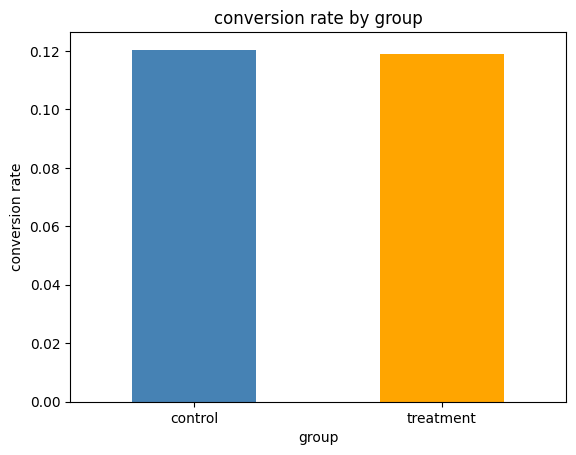

In [11]:
import matplotlib.pyplot as plt
rates["mean"].plot(kind="bar",color=["steelblue","orange"])
plt.title("conversion rate by group")
plt.ylabel("conversion rate")
plt.xticks(rotation=0)
plt.show()

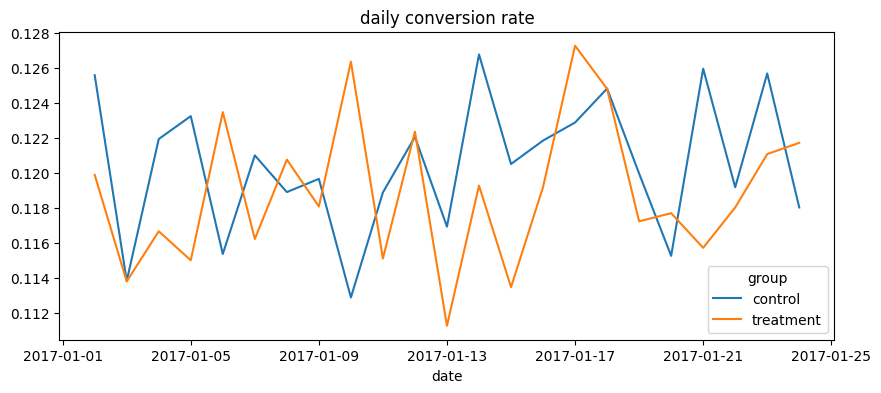

In [12]:
df2["timestamp"] = pd.to_datetime(df2["timestamp"])
df2["date"] = df2["timestamp"].dt.date
daily = df2.groupby(["date","group"])["converted"].mean().unstack()
daily.plot(figsize=(10,4),title="daily conversion rate")
plt.show()

In [13]:
print(rates)

               mean    sum   count
group                             
control    0.120386  17489  145274
treatment  0.118808  17264  145310


In [14]:
control = df2[df2["group"] == "control"]["converted"]
treat = df2[df2["group"] == "treatment"]["converted"]

p_c,p_t = control.mean(),treat.mean()
print("control rate:",round(p_c,5))
print("treatment rate:",round(p_t,5))
print("difference(treatment - control):",round(p_t - p_c, 5))

control rate: 0.12039
treatment rate: 0.11881
difference(treatment - control): -0.00158


In [15]:
from statsmodels.stats.proportion import proportions_ztest

count = [treat.sum(),control.sum()]
nobs = [len(treat), len(control)]

z,p = proportions_ztest(count,nobs,alternative="two-sided")
print("z-stat:",round(z,4))
print("p-value:",round(p,4))

z-stat: -1.3109
p-value: 0.1899


In [19]:
from statsmodels.stats.proportion import confint_proportions_2indep

low, high = confint_proportions_2indep(
    count[0],nobs[0],count[1],nobs[1],method="wald"
)
print("95% CI:", round(low, 5),"to",round(high,5))

95% CI: -0.00394 to 0.00078


In [21]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df2["group"],df2["converted"])
chi2, p_chi, dof, exp =chi2_contingency(table,correction=False)
print("chi-square p-value:",round(p_chi, 4))

chi-square p-value: 0.1899


In [22]:
import numpy as np
np.random.seed(42)

boot_c = np.random.binomial(len(control),p_c,10000) / len(control)
boot_t = np.random.binomial(len(treat),p_t,10000) / len(treat)
diffs = boot_t - boot_c

print("bootstrap 95% ci:", np.percentile(diffs,[2.5,97.5]))

bootstrap 95% ci: [-0.00387701  0.00074813]


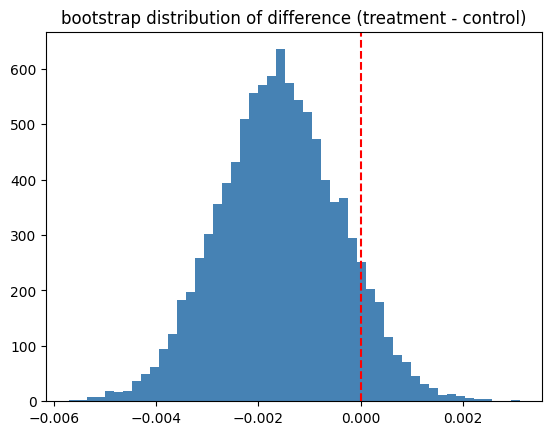

In [24]:
import matplotlib.pyplot as plt
plt.hist(diffs, bins=50, color="steelblue")
plt.axvline(0, color="red",linestyle="--")
plt.title("bootstrap distribution of difference (treatment - control)")
plt.show()

In [26]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

for mde in [0.01,0.005]:
  effect = proportion_effectsize(p_c+mde,p_c)
  n= NormalIndPower().solve_power(effect_size=effect, alpha=0.05,
                                  power=0.8, ratio=1,alternative="two-sided")
  print(f"to fetect a {mde*100} point lift: {int(n)} users per group")
  print("users we have per group:",len(control),len(treat))

to fetect a 1.0 point lift: 17208 users per group
users we have per group: 145274 145310
to fetect a 0.5 point lift: 67672 users per group
users we have per group: 145274 145310


In [27]:
summary = pd.DataFrame({
    "control":[len(control),control.sum(),round(p_c*100,3)],
    "treatment":[len(treat),treat.sum(),round(p_t*100,3)]
},index=["users","conversions","conversion rate(%)"])
print(summary)
print("lift (percentage points):",round((p_t - p_c)*100,3))
print("p_value:", round(p,4))
print("95% ci:",round(low*100,3), "to",round(high*100,3),"points")


                       control   treatment
users               145274.000  145310.000
conversions          17489.000   17264.000
conversion rate(%)      12.039      11.881
lift (percentage points): -0.158
p_value: 0.1899
95% ci: -0.394 to 0.078 points


In [28]:
import sqlite3
conn = sqlite3.connect("ab_test.db")
df2["date"] = df2["date"].astype(str)
df2.to_sql("ab_data", conn, if_exists="replace", index=False)

290584

In [34]:
q1 = """
SELECT "group",
COUNT(*) AS users,
SUM(converted) AS conversions,
ROUND(100.0 * SUM(converted) / COUNT(*),3) AS conversion_rate
FROM ab_data
GROUP BY "group";
"""
pd.read_sql(q1,conn)

,group,users,conversions,conversion_rate
0,control,145274,17489,12.039
1,treatment,145310,17264,11.881


In [37]:
q2 = """
select landing_page,
sum(case when converted = 1 then 1 else 0 end) as converted_users,
sum(case when converted = 0 then 1 else 0 end) as not_converted
from ab_data
group by landing_page;
"""
pd.read_sql(q2,conn)

,landing_page,converted_users,not_converted
0,new_page,17264,128046
1,old_page,17489,127785


In [39]:
q3 = """
with daily aS(
SELECT date, "group",
count(*) as users,
sum(converted) as conv
from ab_data
group by date, "group"
)
select date,"group",users,
round(100.0 * conv / users,2) as rate
from daily
order by date,"group"
limit 10;
"""
pd.read_sql(q3,conn)

,date,group,users,rate
0,2017-01-02,control,2859,12.56
1,2017-01-02,treatment,2853,11.99
2,2017-01-03,control,6590,11.38
3,2017-01-03,treatment,6618,11.38
4,2017-01-04,control,6578,12.19
5,2017-01-04,treatment,6541,11.66
6,2017-01-05,control,6427,12.32
7,2017-01-05,treatment,6505,11.50
8,2017-01-06,control,6606,11.53
9,2017-01-06,treatment,6747,12.35


In [40]:
sql_text = """
-- conversion rate by group
SELECT "group",
COUNT(*) AS users,
SUM(converted) AS conversions,
ROUND(100.0 * SUM(converted) / COUNT(*), 3) AS conversion_rate
FROM ab_data
GROUP BY "group";

-- coverted vs not converted by page
SELECT landing_page,
SUM(CASE WHEN converted = 1 THEN 1 ELSE 0 END) AS converted_users,
SUM(CASE WHEN converted = 0 THEN 1 ELSE 0 END) AS not_converted
FROM ab_data
GROUP BY landind_page;

-- daily conversion rate by group
WITH daily AS (
SELECT date,"group",
COUNT(*) AS users,
SUM(converted) AS conv
FROM ab_data
GROUP BY date,"group"
)
SELECT date,"group",users,
ROUND(100.0 * conv / users,2) as rate
FROM daily
ORDER BY date,"group";
"""

with open("ab_test_queries.sql", "w") as f:
  f.write(sql_text)

  from google.colab import files
  files.download("ab_test_queries.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
df2.to_csv("ab_dashboard_data.csv",index=False)
from google.colab import files
files.download("ab_dashboard_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>